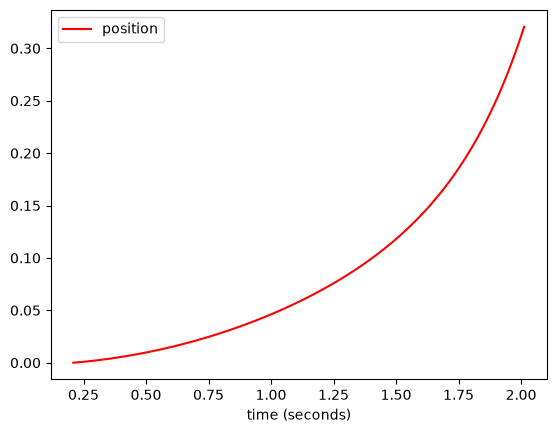

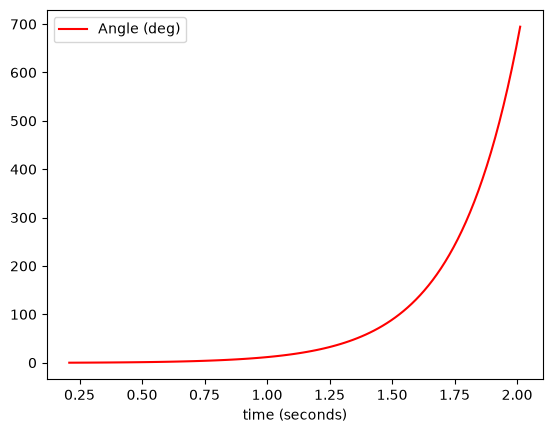

In [4]:
#
# test_inv_pendulum
#

import math
import arslabrobotics as ar

# cart mass = 10 kg
# pendulum mass = 0.5 kg
# pendulum length = 0.5 m
pendulum = ar.system.InvertedPendulum(10.0, 0.5, 0.9, .5)

dpp = ar.data.DataPlotter()
dpp.set_x("time (seconds)")
dpp.add_y("pos", "position")

dpa = ar.data.DataPlotter()
dpa.set_x("time (seconds)")
dpa.add_y("angle", "Angle (deg)")

dds = ar.dds.DDS()
dds.start()

dds.subscribe(['tick'])

_in = 1 # N

t = ar.utils.Time()
t.start()
while t.get() < 2:

    dds.wait('tick')
    
    delta_t = t.elapsed()

    pendulum.evaluate(delta_t, _in)
    (p, v, angle, omega) = pendulum.get_status()

    dds.publish('position', p, ar.dds.DDS_TYPE_FLOAT)
    dds.publish('angle', angle, ar.dds.DDS_TYPE_FLOAT)

    dpp.append_x(t.get())
    dpp.append_y("pos", p)
    
    dpa.append_x(t.get())
    dpa.append_y("angle", math.degrees(angle))

dpp.plot()
dpa.plot()

dds.stop()

